In [11]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [12]:
# Reading the saved data pickle file
rng = pd.date_range('2019-02-24', periods=661, freq='T')
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)
df_companies=pd.read_pickle('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/data/pkl/press_release_companies_statistics.pkl', compression=None)

In [13]:
df_companies

,companies,count
0,MMM,92
1,ABT,74
2,ABBV,118
3,ABMD,26
4,ACN,151
...,...,...
500,YUM,50
501,ZBRA,29
502,ZBH,19
503,ZION,21


In [14]:
df["articles"].describe()
df = df.join(df_sentiment)
df[["VIX"]] = df["adj close"].apply(np.int)
df["log_VIX"]=np.log(df["VIX"]/df["VIX"].shift(1))
df[['sentiment']] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(20).mean()
df['vix_ln_return'] = np.log(df['VIX']/df['VIX'].shift(1))
df['vix_ln_return_ewm100']=df['vix_ln_return'].ewm(span=100).mean()#.plot(title='vix ln returns')
df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_companies['count'] = df_companies['count'].apply(pd.to_numeric)

In [15]:
df

,close,adj close,articles,compound,neg,neu,pos,sentiment,sentiment_complementary,VIX,log_VIX,sentiment_ewm,vix_ln_return,vix_ln_return_ewm100,date
2019-09-25,15.960000,15.960000,FDA Approves Abbott's Low Dose Recharge-Free S...,1.0,0.015,0.879,0.106,87.603306,12.396694,15,NaN,87.603306,NaN,NaN,2019-09-25
2019-09-26,16.070000,16.070000,"FDA Approves Abbott's ""Low Dose,"" Recharge-Fre...",1.0,0.022,0.859,0.118,84.285714,15.714286,16,0.064539,85.904052,0.064539,0.064539,2019-09-26
2019-09-27,17.219999,17.219999,New Data Demonstrate Strong Outcomes for Abbot...,0.9998,0.033,0.862,0.105,76.086957,23.913043,17,0.060625,82.470793,0.060625,0.062562,2019-09-27
2019-09-28,16.893333,16.893333,NaN,0,0,0,0,NaN,NaN,16,-0.060625,82.470793,-0.060625,0.020676,2019-09-28
2019-09-29,16.566666,16.566666,NaN,0,0,0,0,NaN,NaN,16,0.000000,82.470793,0.000000,0.015351,2019-09-29
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-07-12,16.170000,16.170000,3M Oral Care Introduces Next-Generation Clear ...,0.9999,0.013,0.848,0.138,91.390728,8.609272,16,0.000000,88.031086,0.000000,-0.001636,2021-07-12
2021-07-13,17.120001,17.120001,3M Announces Upcoming Investor Event. ST. PAUL...,1.0,0.011,0.843,0.146,92.993631,7.006369,17,0.060625,88.383578,0.060625,-0.000403,2021-07-13
2021-07-14,16.330000,16.330000,Cybersecurity Executive Rick Driggers Joins Ac...,0.9999,0.01,0.874,0.116,92.063492,7.936508,16,-0.060625,88.638984,-0.060625,-0.001595,2021-07-14
2021-07-15,16.330000,16.330000,Air Products Declares Quarterly Dividend. LEHI...,1.0,0.016,0.817,0.166,91.208791,8.791209,16,0.000000,88.813539,0.000000,-0.001564,2021-07-15


<AxesSubplot:ylabel='Frequency'>

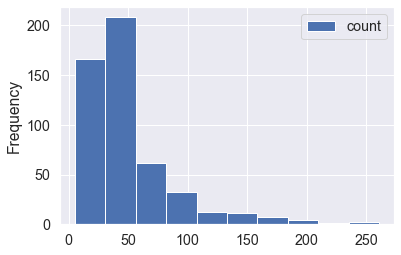

In [16]:
df_companies.plot(kind="hist")

In [23]:
ax = sns.barplot(x="day", y="tip", data=df["sentiment"], ci="sd")


ValueError: Could not interpret input 'day'



In [26]:
cols = (df_companies[["companies", "count"]]
        .groupby("companies")
        .mean()
        .sort_values(by="count", ascending=False)[:150].index)
# best_features = df_companies.loc[feature_importance_df.Feature.isin(cols)]

plt.figure(figsize=(20,150))
chart=sns.barplot(x="count", y="companies", data=df_companies.sort_values(by="count",ascending=False))
chart.bar_label(chart.containers[0])
plt.title('S&P500 Companies by Press Release Count')
plt.tight_layout()
plt.savefig('/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/S&P500 Companies by Press Release Count.png')